In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
df = pd.read_csv(r"G:\UNIFIED MENTOR - DATA ANALYTiCS INTERNSHIP\ALL PROJECTS\Ferry_Capacity_Analytics\dataset\Toronto Island Ferry Tickets.csv")

In [3]:
df.head()

,_id,Timestamp,Redemption Count,Sales Count
0,1,2025-12-21T22:30:00,14,16
1,2,2025-12-21T22:15:00,1,0
2,3,2025-12-21T22:00:00,2,0
3,4,2025-12-21T21:30:00,11,1
4,5,2025-12-21T21:15:00,10,0


In [4]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 261538
Number of Columns: 4


In [5]:
df.describe()

,_id,Redemption Count,Sales Count
count,261538.000000,261538.000000,261538.000000
mean,130769.500000,48.885030,49.599106
std,75499.661689,104.549336,99.862285
min,1.000000,0.000000,0.000000
25%,65385.250000,3.000000,3.000000
50%,130769.500000,11.000000,13.000000
75%,196153.750000,40.000000,48.000000
max,261538.000000,7216.000000,7229.000000


In [6]:
df.isnull().sum()

_id                 0
Timestamp           0
Redemption Count    0
Sales Count         0
dtype: int64

In [7]:
df.isnull().sum()

_id                 0
Timestamp           0
Redemption Count    0
Sales Count         0
dtype: int64

In [8]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 261538 entries, 0 to 261537
Data columns (total 4 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   _id               261538 non-null  int64         
 1   Timestamp         261538 non-null  datetime64[us]
 2   Redemption Count  261538 non-null  int64         
 3   Sales Count       261538 non-null  int64         
dtypes: datetime64[us](1), int64(3)
memory usage: 8.0 MB


In [9]:
df.isnull().sum()

_id                 0
Timestamp           0
Redemption Count    0
Sales Count         0
dtype: int64

In [10]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [11]:
print("Negative Sales:", (df['Sales Count'] < 0).sum())

print("Negative Redemptions:", (df['Redemption Count'] < 0).sum())

Negative Sales: 0
Negative Redemptions: 0


In [12]:
print("Total Tickets Sold:", df['Sales Count'].sum())

print("Total Tickets Redeemed:", df['Redemption Count'].sum())

print("Average Sales:", df['Sales Count'].mean())

print("Average Redemption:", df['Redemption Count'].mean())

print("Maximum Sales:", df['Sales Count'].max())

print("Maximum Redemption:", df['Redemption Count'].max())

Total Tickets Sold: 12972051
Total Tickets Redeemed: 12785293
Average Sales: 49.59910605724598
Average Redemption: 48.885030091229574
Maximum Sales: 7229
Maximum Redemption: 7216


In [13]:
activity = pd.DataFrame({
    'Activity': ['Tickets Sold', 'Tickets Redeemed'],
    'Count': [
        df['Sales Count'].sum(),
        df['Redemption Count'].sum()
    ]
})

activity

,Activity,Count
0,Tickets Sold,12972051
1,Tickets Redeemed,12785293


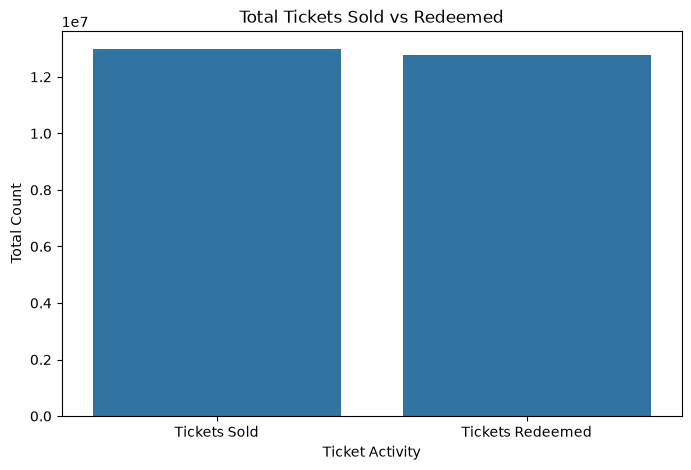

In [14]:
plt.figure(figsize=(8,5))

sns.barplot(data=activity, x='Activity', y='Count')

plt.title('Total Tickets Sold vs Redeemed')
plt.xlabel('Ticket Activity')
plt.ylabel('Total Count')

plt.show()

In [15]:
df['Year'] = df['Timestamp'].dt.year

In [16]:
yearly_activity = df.groupby('Year')[[
    'Sales Count',
    'Redemption Count'
]].sum().reset_index()

yearly_activity

,Year,Sales Count,Redemption Count
0,2015,1189620,978707
1,2016,1518428,1425779
2,2017,682346,698861
3,2018,1463589,1493560
4,2019,1249725,1278505
5,2020,366606,374546
6,2021,782368,773040
7,2022,1346659,1349778
8,2023,1491473,1502883
9,2024,1373563,1390358


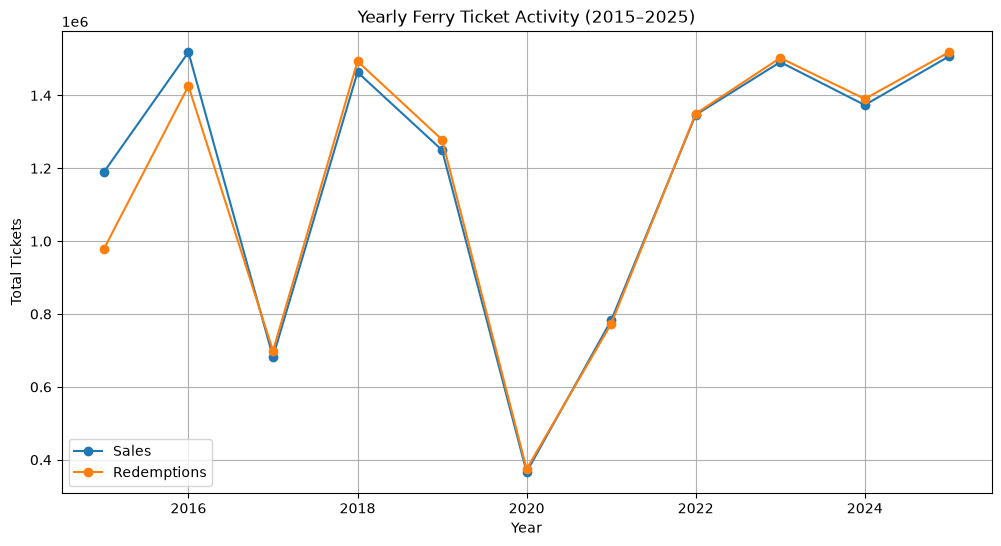

In [17]:
plt.figure(figsize=(12,6))

plt.plot(yearly_activity['Year'],
         yearly_activity['Sales Count'],
         marker='o',
         label='Sales')

plt.plot(yearly_activity['Year'],
         yearly_activity['Redemption Count'],
         marker='o',
         label='Redemptions')

plt.title('Yearly Ferry Ticket Activity (2015–2025)')
plt.xlabel('Year')
plt.ylabel('Total Tickets')

plt.legend()
plt.grid(True)

plt.show()

In [18]:
df['Month'] = df['Timestamp'].dt.month

df['Month_Name'] = df['Timestamp'].dt.month_name()

In [19]:
monthly_activity = df.groupby('Month_Name')[
    ['Sales Count', 'Redemption Count']
].sum().reset_index()

In [20]:
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_activity['Month_Name'] = pd.Categorical(
    monthly_activity['Month_Name'],
    categories=month_order,
    ordered=True
)

monthly_activity = monthly_activity.sort_values('Month_Name')

monthly_activity

,Month_Name,Sales Count,Redemption Count
4,January,130455,151620
3,February,146179,168535
7,March,201753,222769
0,April,401395,402168
8,May,1090751,1039836
6,June,1814395,1712766
5,July,3083858,2909572
1,August,3442762,3378623
11,September,1605867,1639862
10,October,638215,672594


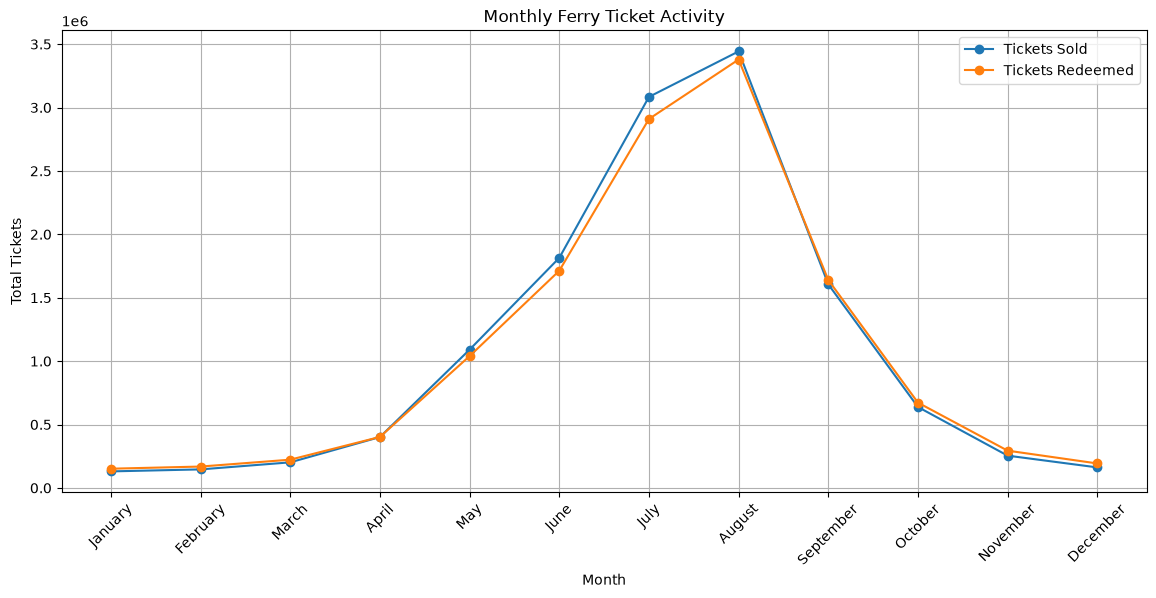

In [21]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_activity['Month_Name'],
    monthly_activity['Sales Count'],
    marker='o',
    label='Tickets Sold'
)

plt.plot(
    monthly_activity['Month_Name'],
    monthly_activity['Redemption Count'],
    marker='o',
    label='Tickets Redeemed'
)

plt.title('Monthly Ferry Ticket Activity')
plt.xlabel('Month')
plt.ylabel('Total Tickets')

plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

plt.show()

In [22]:
peak_month = monthly_activity.loc[
    monthly_activity['Redemption Count'].idxmax()
]

lowest_month = monthly_activity.loc[
    monthly_activity['Redemption Count'].idxmin()
]

print("Peak Activity Month:", peak_month['Month_Name'])
print("Highest Redemptions:", peak_month['Redemption Count'])

print("\nLowest Activity Month:", lowest_month['Month_Name'])
print("Lowest Redemptions:", lowest_month['Redemption Count'])

Peak Activity Month: August
Highest Redemptions: 3378623

Lowest Activity Month: January
Lowest Redemptions: 151620


In [23]:
def get_season(month):
    if month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    elif month in [9, 10, 11]:
        return 'Autumn'
    else:
        return 'Winter'

df['Season'] = df['Timestamp'].dt.month.apply(get_season)

In [24]:
seasonal_activity = df.groupby('Season')[
    ['Sales Count', 'Redemption Count']
].sum().reindex([
    'Spring', 'Summer', 'Autumn', 'Winter'
]).reset_index()

seasonal_activity

,Season,Sales Count,Redemption Count
0,Spring,1693899,1664773
1,Summer,8341015,8000961
2,Autumn,2498657,2606380
3,Winter,438480,513179


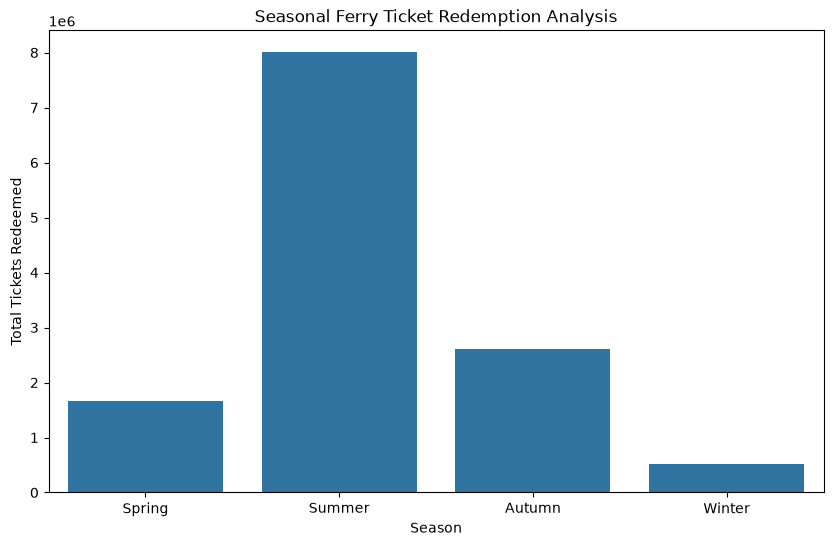

In [25]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=seasonal_activity,
    x='Season',
    y='Redemption Count'
)

plt.title('Seasonal Ferry Ticket Redemption Analysis')
plt.xlabel('Season')
plt.ylabel('Total Tickets Redeemed')

plt.show()

In [26]:
seasonal_activity['Redemption Ratio'] = (
    seasonal_activity['Redemption Count'] /
    seasonal_activity['Sales Count'].replace(0, np.nan)
) * 100

seasonal_activity

,Season,Sales Count,Redemption Count,Redemption Ratio
0,Spring,1693899,1664773,98.280535
1,Summer,8341015,8000961,95.923110
2,Autumn,2498657,2606380,104.311236
3,Winter,438480,513179,117.035897


In [27]:
df['Date'] = df['Timestamp'].dt.date

df['Day_Name'] = df['Timestamp'].dt.day_name()

In [28]:
daily_activity = df.groupby('Date')[
    ['Sales Count', 'Redemption Count']
].sum().reset_index()

daily_activity.head()

,Date,Sales Count,Redemption Count
0,2015-05-01,4,1
1,2015-05-04,75,12
2,2015-05-05,549,537
3,2015-05-06,1358,989
4,2015-05-07,2170,1343


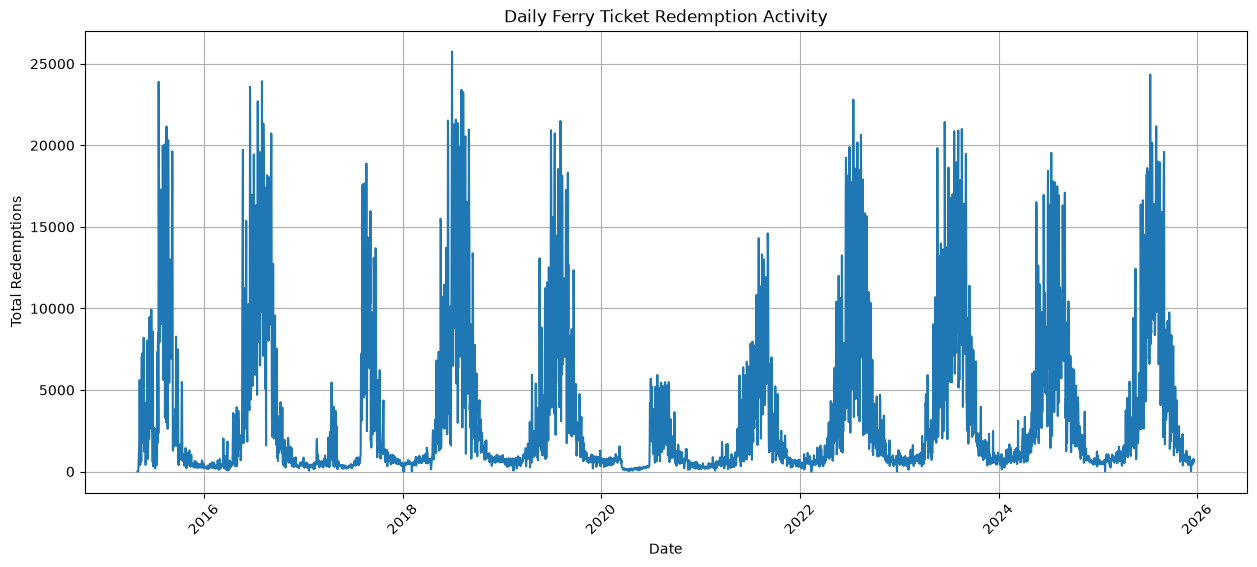

In [29]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_activity['Date'],
    daily_activity['Redemption Count']
)

plt.title('Daily Ferry Ticket Redemption Activity')
plt.xlabel('Date')
plt.ylabel('Total Redemptions')

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [30]:
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_activity = df.groupby('Day_Name')[
    ['Sales Count', 'Redemption Count']
].sum().reindex(day_order).reset_index()

weekday_activity

,Day_Name,Sales Count,Redemption Count
0,Monday,1670609,1654352
1,Tuesday,1331860,1271089
2,Wednesday,1444624,1383026
3,Thursday,1461639,1379066
4,Friday,1784931,1621026
5,Saturday,2727394,2795008
6,Sunday,2550994,2681726


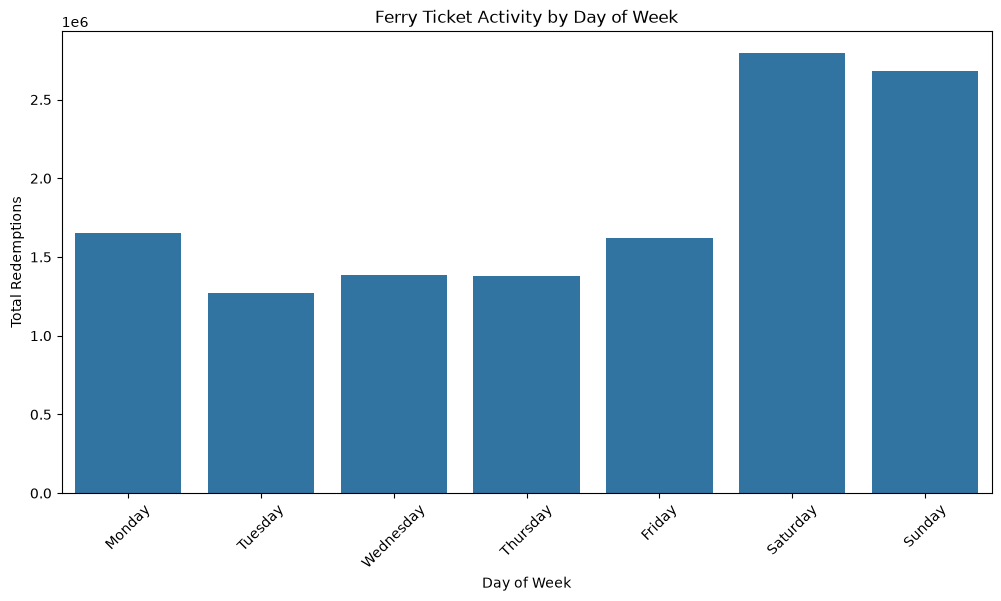

In [31]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=weekday_activity,
    x='Day_Name',
    y='Redemption Count'
)

plt.title('Ferry Ticket Activity by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Total Redemptions')

plt.xticks(rotation=45)
plt.show()

In [32]:
df['Day_Type'] = np.where(
    df['Timestamp'].dt.dayofweek >= 5,
    'Weekend',
    'Weekday'
)

In [33]:
day_type_activity = df.groupby('Day_Type')[
    ['Sales Count', 'Redemption Count']
].sum().reset_index()

day_type_activity

,Day_Type,Sales Count,Redemption Count
0,Weekday,7693663,7308559
1,Weekend,5278388,5476734


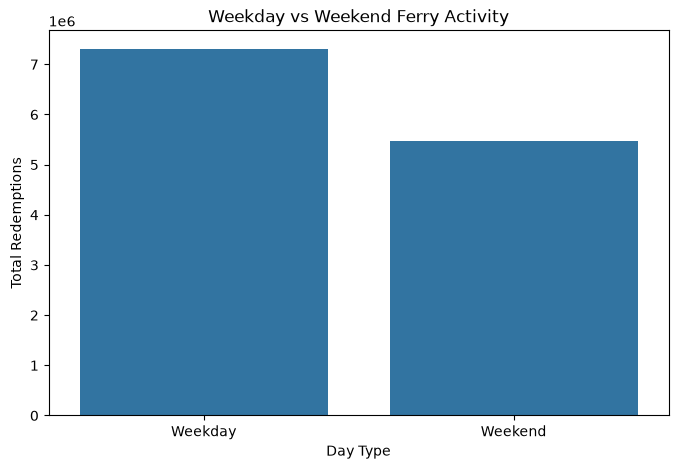

In [34]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=day_type_activity,
    x='Day_Type',
    y='Redemption Count'
)

plt.title('Weekday vs Weekend Ferry Activity')
plt.xlabel('Day Type')
plt.ylabel('Total Redemptions')

plt.show()

In [35]:
df['Hour'] = df['Timestamp'].dt.hour

In [36]:
hourly_activity = df.groupby('Hour')[
    ['Sales Count', 'Redemption Count']
].sum().reset_index()

hourly_activity

,Hour,Sales Count,Redemption Count
0,0,55357,356
1,1,24314,2232
2,2,11131,3475
3,3,6734,3357
4,4,3440,2289
5,5,5611,2151
6,6,71790,84667
7,7,140104,108757
8,8,352362,256088
9,9,756876,674964


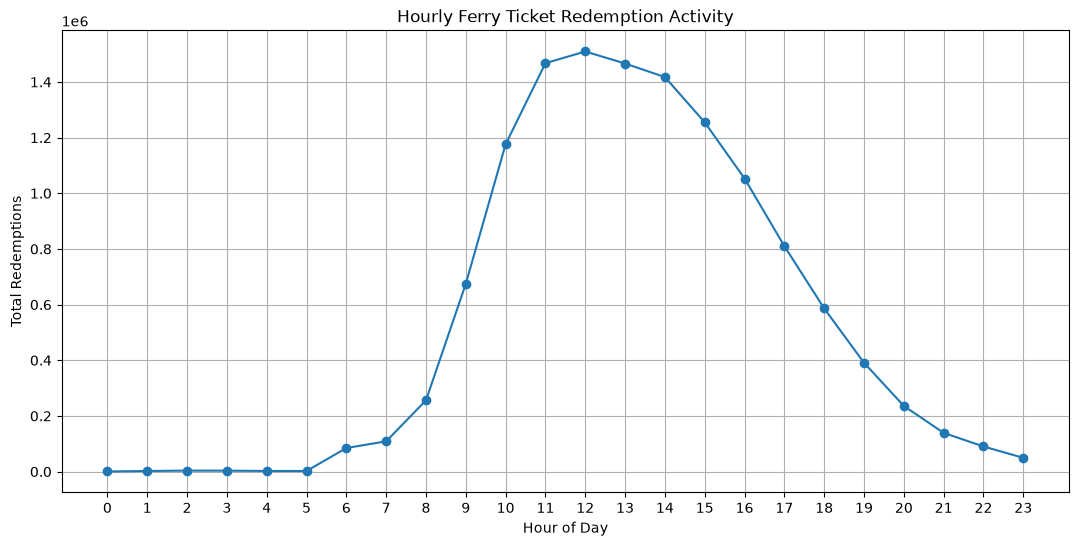

In [37]:
plt.figure(figsize=(13, 6))

plt.plot(
    hourly_activity['Hour'],
    hourly_activity['Redemption Count'],
    marker='o'
)

plt.title('Hourly Ferry Ticket Redemption Activity')
plt.xlabel('Hour of Day')
plt.ylabel('Total Redemptions')

plt.xticks(range(0, 24))
plt.grid(True)

plt.show()

In [38]:
peak_hour = hourly_activity.loc[
    hourly_activity['Redemption Count'].idxmax()
]

lowest_hour = hourly_activity.loc[
    hourly_activity['Redemption Count'].idxmin()
]

print("Peak Activity Hour:", peak_hour['Hour'])
print("Peak Redemptions:", peak_hour['Redemption Count'])

print("\nLowest Activity Hour:", lowest_hour['Hour'])
print("Lowest Redemptions:", lowest_hour['Redemption Count'])

Peak Activity Hour: 12
Peak Redemptions: 1509483

Lowest Activity Hour: 0
Lowest Redemptions: 356


In [39]:
df['Total_Activity_Load'] = (
    df['Sales Count'] + df['Redemption Count']
)

df[['Timestamp', 'Sales Count',
    'Redemption Count', 'Total_Activity_Load']].head()

,Timestamp,Sales Count,Redemption Count,Total_Activity_Load
0,2025-12-21 22:30:00,16,14,30
1,2025-12-21 22:15:00,0,1,1
2,2025-12-21 22:00:00,0,2,2
3,2025-12-21 21:30:00,1,11,12
4,2025-12-21 21:15:00,0,10,10


In [40]:
df['Redemption_Pressure_Ratio'] = (
    df['Redemption Count'] /
    (df['Sales Count'] + 1)
)

df[['Timestamp', 'Redemption_Pressure_Ratio']].head()

,Timestamp,Redemption_Pressure_Ratio
0,2025-12-21 22:30:00,0.823529
1,2025-12-21 22:15:00,1.000000
2,2025-12-21 22:00:00,2.000000
3,2025-12-21 21:30:00,5.500000
4,2025-12-21 21:15:00,10.000000


In [41]:
min_load = df['Redemption Count'].min()
max_load = df['Redemption Count'].max()

if max_load > min_load:
    df['OLI'] = (
        (df['Redemption Count'] - min_load) /
        (max_load - min_load)
    ) * 100
else:
    df['OLI'] = 0

df[['Timestamp', 'Redemption Count', 'OLI']].head()

,Timestamp,Redemption Count,OLI
0,2025-12-21 22:30:00,14,0.194013
1,2025-12-21 22:15:00,1,0.013858
2,2025-12-21 22:00:00,2,0.027716
3,2025-12-21 21:30:00,11,0.152439
4,2025-12-21 21:15:00,10,0.138581


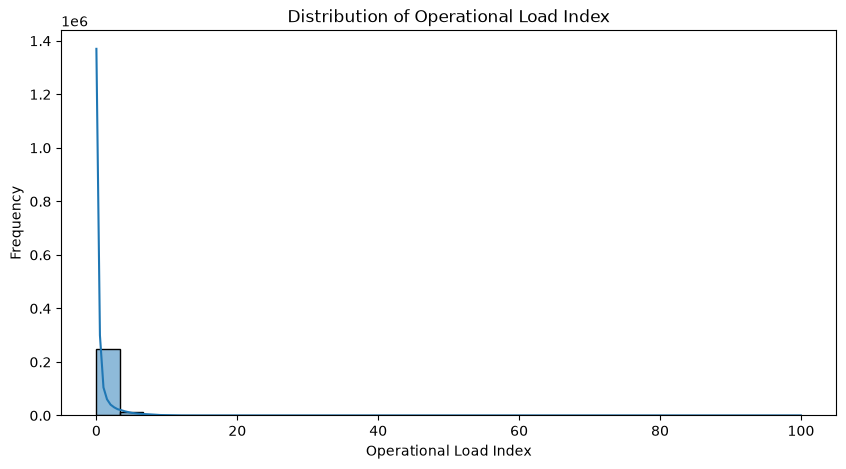

In [42]:
plt.figure(figsize=(10, 5))

sns.histplot(df['OLI'], bins=30, kde=True)

plt.title('Distribution of Operational Load Index')
plt.xlabel('Operational Load Index')
plt.ylabel('Frequency')

plt.show()

In [43]:
congestion_threshold = df['Redemption Count'].quantile(0.90)

df['Congestion_Status'] = np.where(
    df['Redemption Count'] >= congestion_threshold,
    'High Activity',
    'Normal Activity'
)

print("Congestion Threshold:", congestion_threshold)

print(df['Congestion_Status'].value_counts())

Congestion Threshold: 143.0
Congestion_Status
Normal Activity    235303
High Activity       26235
Name: count, dtype: int64


In [44]:
idle_threshold = df['Redemption Count'].quantile(0.10)

print("Idle Activity Threshold:", idle_threshold)

Idle Activity Threshold: 0.0


In [45]:
df['Idle_Status'] = np.where(
    df['Redemption Count'] <= idle_threshold,
    'Low Activity',
    'Normal Activity'
)

df['Idle_Status'].value_counts()

Idle_Status
Normal Activity    233708
Low Activity        27830
Name: count, dtype: int64

In [46]:
operational_summary = pd.DataFrame({
    'Category': [
        'High Activity',
        'Normal Activity',
        'Low Activity'
    ],
    'Intervals': [
        (df['Congestion_Status'] == 'High Activity').sum(),
        (
            (df['Congestion_Status'] == 'Normal Activity') &
            (df['Idle_Status'] == 'Normal Activity')
        ).sum(),
        (df['Idle_Status'] == 'Low Activity').sum()
    ]
})

operational_summary

,Category,Intervals
0,High Activity,26235
1,Normal Activity,207473
2,Low Activity,27830


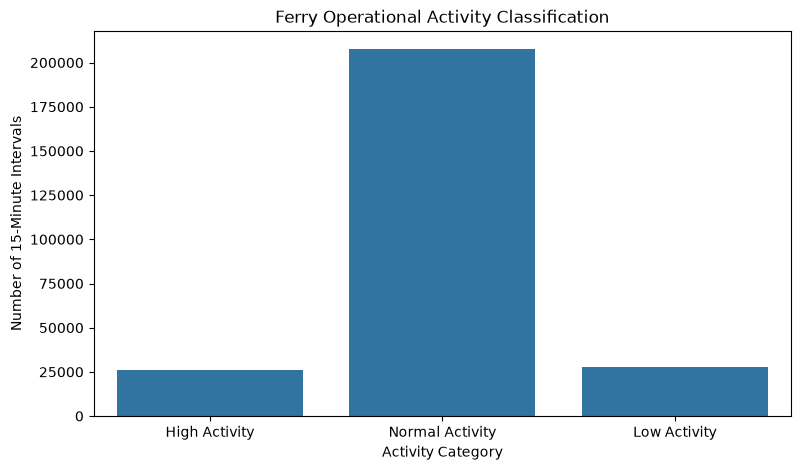

In [47]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=operational_summary,
    x='Category',
    y='Intervals'
)

plt.title('Ferry Operational Activity Classification')
plt.xlabel('Activity Category')
plt.ylabel('Number of 15-Minute Intervals')

plt.show()

In [48]:
df['Day_Name'] = df['Timestamp'].dt.day_name()
df['Hour'] = df['Timestamp'].dt.hour

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

hour_day_data = df.pivot_table(
    index='Day_Name',
    columns='Hour',
    values='Redemption Count',
    aggfunc='mean'
)

hour_day_data = hour_day_data.reindex(day_order)

hour_day_data

Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Day_Name,,,,,,,,,,,,,,,,,,,,,
Monday,0.343653,0.006550,0.315068,1.351190,0.150376,1.250000,9.997569,7.098419,16.890204,43.646827,...,85.406982,73.010256,60.492814,50.439586,35.439747,25.472060,14.435842,11.010995,8.689445,4.101865
Tuesday,0.011589,4.335859,3.425532,0.647887,11.142857,0.713514,11.169355,7.167160,16.133617,37.897129,...,62.308888,53.604956,46.369545,36.339792,30.447776,22.135699,17.185024,8.560136,5.689326,3.290984
Wednesday,0.000000,0.000000,0.000000,0.000000,0.016129,0.005181,11.960979,8.138821,17.421298,43.358309,...,63.391762,54.675150,48.103717,37.672710,30.947797,25.381912,14.101613,10.341137,7.396085,3.546433
Thursday,0.027821,0.016509,0.621324,2.171429,0.000000,0.005650,11.002379,8.017970,16.764733,41.779856,...,64.220723,52.733364,46.363553,39.717290,31.929119,23.595887,14.279365,10.142857,6.461321,6.439547
Friday,0.049598,0.088725,3.160714,2.701357,3.045198,0.350394,8.528423,6.996569,17.041764,47.048944,...,77.648456,66.270929,57.622069,46.391729,39.086812,30.766734,19.051242,11.384163,6.475248,4.455237
Saturday,0.005313,0.609333,1.748148,1.134247,2.304348,2.915014,9.008145,9.601381,17.526235,54.345244,...,160.349765,141.423394,119.110181,89.379375,60.536528,40.682096,25.747912,15.382010,8.571671,5.022840
Sunday,0.072354,0.000000,0.804391,4.945946,0.121212,2.244966,10.511307,11.747820,23.300664,60.031770,...,156.553867,138.970711,110.017274,80.488294,53.217667,34.303270,21.160665,11.453608,9.632872,5.935055


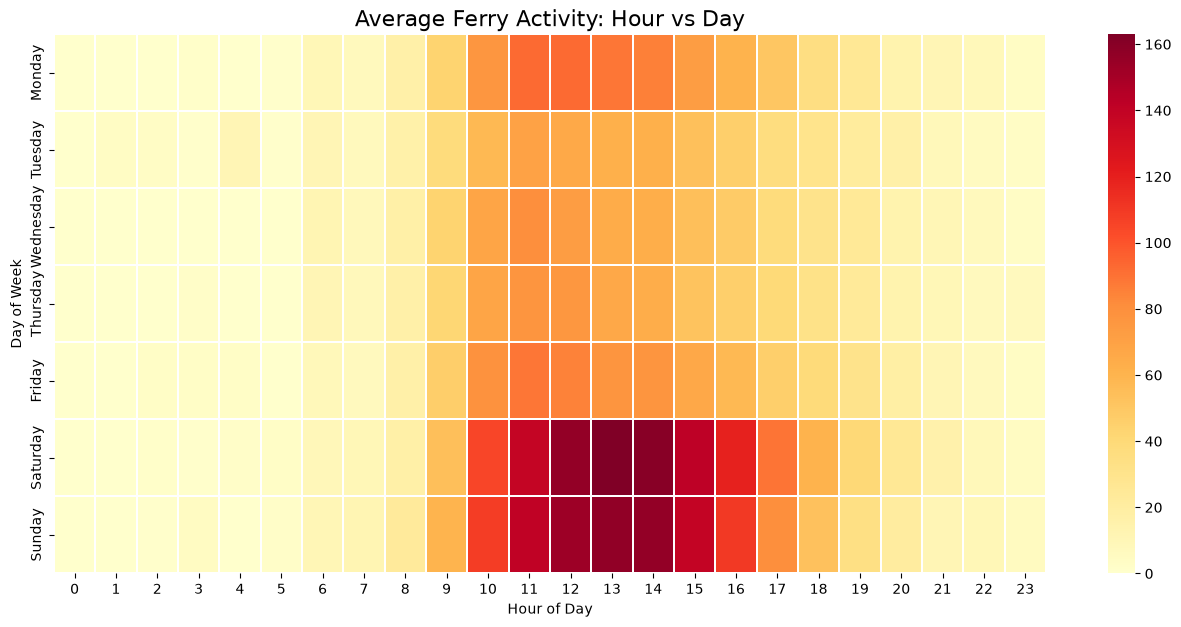

In [49]:
plt.figure(figsize=(16, 7))

sns.heatmap(
    hour_day_data,
    cmap='YlOrRd',
    linewidths=0.3,
    annot=False
)

plt.title('Average Ferry Activity: Hour vs Day',
          fontsize=16)

plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')

plt.show()

In [50]:
df['Year'] = df['Timestamp'].dt.year
df['Month'] = df['Timestamp'].dt.month

monthly_heatmap = df.pivot_table(
    index='Year',
    columns='Month',
    values='Redemption Count',
    aggfunc='mean'
)

monthly_heatmap

Month,1,2,3,4,5,6,7,8,9,10,11,12
Year,,,,,,,,,,,,
2015,NaN,NaN,NaN,NaN,46.987296,58.724688,101.346026,152.671746,74.961045,22.630460,10.424393,7.371483
2016,5.826782,6.710105,9.757179,17.876712,59.655172,100.308932,148.241785,148.255591,81.204941,27.554752,13.200573,7.879553
2017,7.124605,10.401422,8.884000,26.235844,8.620474,6.100418,12.989738,113.713586,79.334396,32.241114,12.048250,9.193770
2018,8.653972,9.635853,12.036059,16.390132,61.747101,98.368172,157.842674,146.781401,80.402019,27.774347,14.132837,12.021682
2019,10.498919,10.531982,12.056133,23.612038,40.528172,80.015908,125.494841,143.230832,62.624195,30.125300,13.428419,11.636364
2020,10.662040,10.998299,9.059069,3.126176,3.925824,9.642536,31.993220,37.412711,24.736336,11.830208,10.843697,7.048960
2021,5.271958,6.911323,9.195421,8.911732,21.843416,32.459319,56.011398,83.915832,51.343987,22.322725,14.133469,9.461211
2022,8.553601,9.753152,11.744234,21.768496,51.058725,81.280478,133.288278,120.927576,62.421488,33.037580,17.555611,10.710106
2023,10.231552,12.236547,12.538079,32.414165,66.613456,84.219563,131.063004,132.351225,78.863577,37.392646,16.714796,12.618116


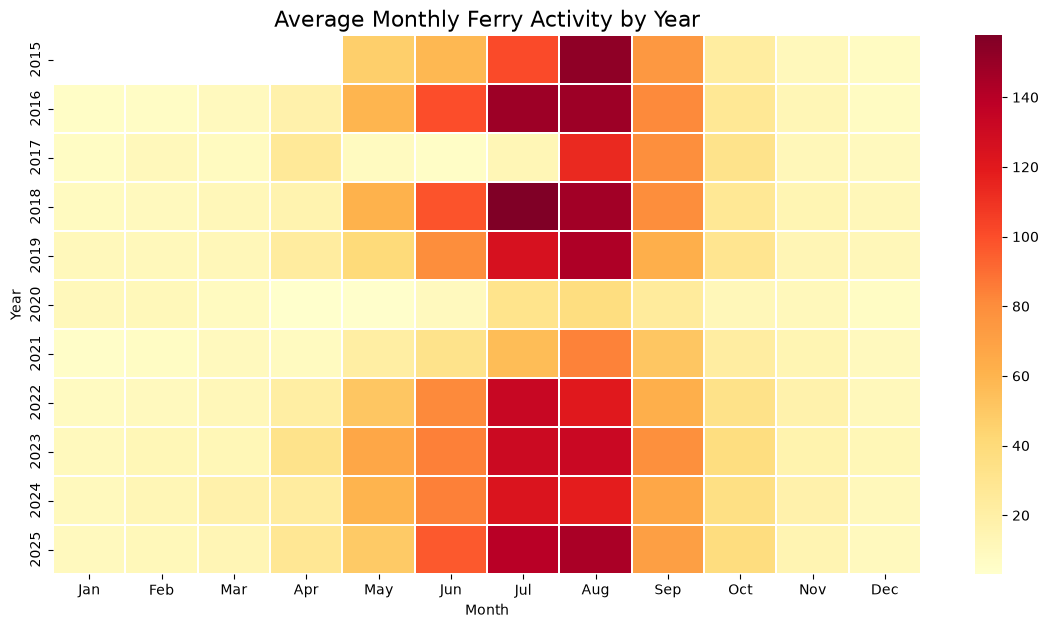

In [51]:
plt.figure(figsize=(14, 7))

sns.heatmap(
    monthly_heatmap,
    cmap='YlOrRd',
    linewidths=0.3,
    annot=False
)

plt.title('Average Monthly Ferry Activity by Year', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Year')

plt.xticks(
    ticks=np.arange(12) + 0.5,
    labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
            'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

plt.show()

In [52]:
year_month_data = df.pivot_table(
    index='Month',
    columns='Year',
    values='Redemption Count',
    aggfunc='mean'
)

year_month_data

Year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Month,,,,,,,,,,,
1,NaN,5.826782,7.124605,8.653972,10.498919,10.662040,5.271958,8.553601,10.231552,10.017118,9.510827
2,NaN,6.710105,10.401422,9.635853,10.531982,10.998299,6.911323,9.753152,12.236547,13.131955,11.233503
3,NaN,9.757179,8.884000,12.036059,12.056133,9.059069,9.195421,11.744234,12.538079,17.948008,13.561815
4,NaN,17.876712,26.235844,16.390132,23.612038,3.126176,8.911732,21.768496,32.414165,23.162136,28.065903
5,46.987296,59.655172,8.620474,61.747101,40.528172,3.925824,21.843416,51.058725,66.613456,59.962932,49.430626
6,58.724688,100.308932,6.100418,98.368172,80.015908,9.642536,32.459319,81.280478,84.219563,84.325591,96.758273
7,101.346026,148.241785,12.989738,157.842674,125.494841,31.993220,56.011398,133.288278,131.063004,123.912692,139.216082
8,152.671746,148.255591,113.713586,146.781401,143.230832,37.412711,83.915832,120.927576,132.351225,118.216153,144.344958
9,74.961045,81.204941,79.334396,80.402019,62.624195,24.736336,51.343987,62.421488,78.863577,66.712180,71.166097


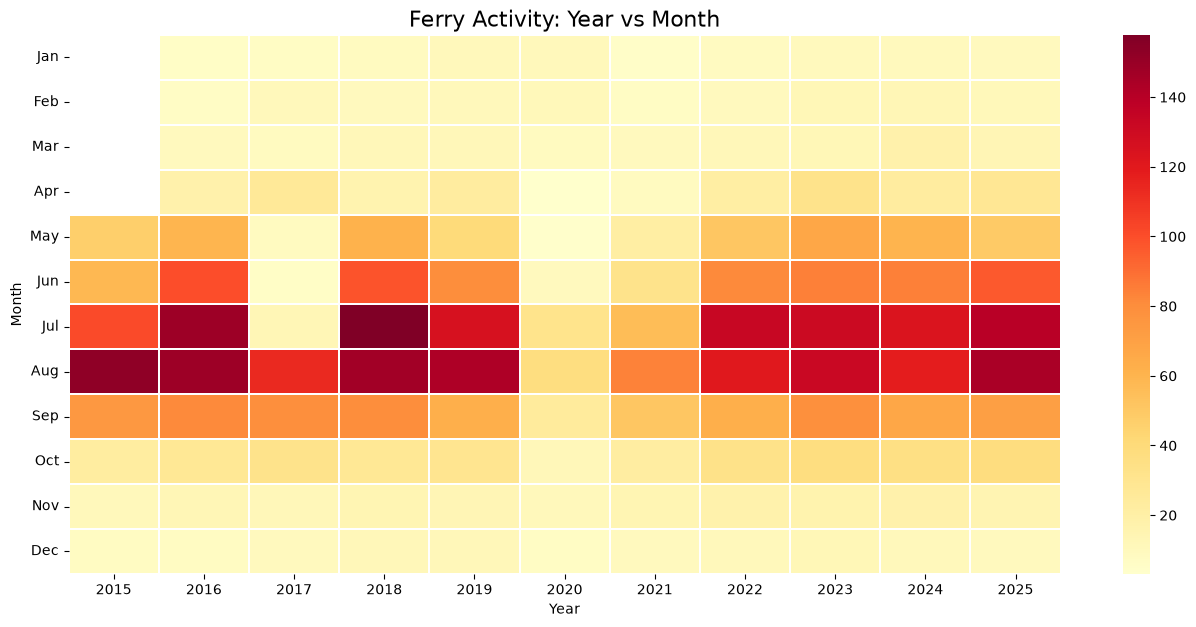

In [53]:
plt.figure(figsize=(16, 7))

sns.heatmap(
    year_month_data,
    cmap='YlOrRd',
    linewidths=0.3,
    annot=False
)

plt.title('Ferry Activity: Year vs Month', fontsize=16)
plt.xlabel('Year')
plt.ylabel('Month')

plt.yticks(
    ticks=np.arange(12) + 0.5,
    labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
            'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'],
    rotation=0
)

plt.show()

In [54]:
high_threshold = df['Redemption Count'].quantile(0.90)

print("High Activity Threshold:", high_threshold)

High Activity Threshold: 143.0


In [55]:
df['High_Activity'] = (
    df['Redemption Count'] >= high_threshold
).astype(int)

high_activity_data = df.pivot_table(
    index='Day_Name',
    columns='Hour',
    values='High_Activity',
    aggfunc='mean'
)

high_activity_data = high_activity_data.reindex(day_order)

high_activity_data

Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Day_Name,,,,,,,,,,,,,,,,,,,,,
Monday,0.001548,0.000000,0.000000,0.000000,0.000000,0.005435,0.001621,0.001530,0.011832,0.107723,...,0.208513,0.174825,0.114975,0.066761,0.037901,0.013305,0.002707,0.006944,0.003661,0.004304
Tuesday,0.000000,0.010101,0.008511,0.000000,0.028571,0.000000,0.000000,0.000986,0.010387,0.093780,...,0.141331,0.107059,0.065460,0.021739,0.014507,0.003653,0.002713,0.002259,0.002982,0.000683
Wednesday,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000487,0.012611,0.109510,...,0.155172,0.124017,0.080312,0.035797,0.017720,0.004651,0.002688,0.003902,0.001727,0.000673
Thursday,0.000000,0.000000,0.003676,0.005714,0.000000,0.000000,0.000793,0.000486,0.012065,0.104077,...,0.155181,0.116913,0.076392,0.040187,0.020115,0.005141,0.002116,0.003846,0.005082,0.001889
Friday,0.000000,0.000000,0.011905,0.009050,0.005650,0.000000,0.000801,0.001961,0.012201,0.119002,...,0.196200,0.158234,0.125517,0.067379,0.036528,0.016734,0.006211,0.003210,0.001650,0.001170
Saturday,0.000000,0.000000,0.005556,0.000000,0.008696,0.008499,0.009955,0.013810,0.013754,0.132303,...,0.340845,0.315138,0.289633,0.244517,0.155598,0.067141,0.011482,0.008329,0.005099,0.003086
Sunday,0.000000,0.000000,0.001996,0.018018,0.000000,0.003356,0.017588,0.022803,0.028239,0.159859,...,0.348527,0.324035,0.276377,0.216436,0.120059,0.041139,0.008310,0.007884,0.010076,0.004695


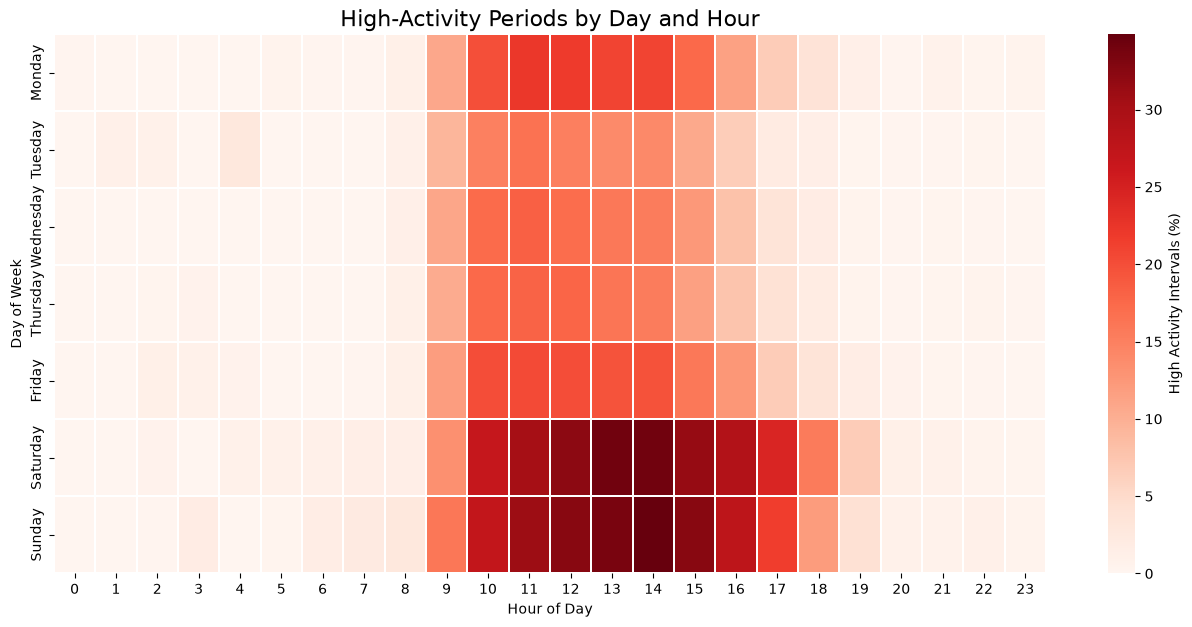

In [56]:
plt.figure(figsize=(16, 7))

sns.heatmap(
    high_activity_data * 100,
    cmap='Reds',
    linewidths=0.3,
    annot=False,
    cbar_kws={'label': 'High Activity Intervals (%)'}
)

plt.title('High-Activity Periods by Day and Hour', fontsize=16)
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')

plt.show()

In [57]:
peak_activity = df.loc[df['Redemption Count'].idxmax()]

lowest_activity = df.loc[df['Redemption Count'].idxmin()]

print("PEAK ACTIVITY PERIOD")
print("Timestamp:", peak_activity['Timestamp'])
print("Redemption Count:", peak_activity['Redemption Count'])

print("\nLOWEST ACTIVITY PERIOD")
print("Timestamp:", lowest_activity['Timestamp'])
print("Redemption Count:", lowest_activity['Redemption Count'])

PEAK ACTIVITY PERIOD
Timestamp: 2023-08-15 20:15:00
Redemption Count: 7216

LOWEST ACTIVITY PERIOD
Timestamp: 2025-12-21 20:00:00
Redemption Count: 0


In [58]:
high_threshold = df['Redemption Count'].quantile(0.90)
low_threshold = df['Redemption Count'].quantile(0.10)

print("High Activity Threshold:", high_threshold)
print("Low Activity Threshold:", low_threshold)

High Activity Threshold: 143.0
Low Activity Threshold: 0.0


In [59]:
high_activity_percentage = (
    (df['Redemption Count'] >= high_threshold).mean() * 100
)

low_activity_percentage = (
    (df['Redemption Count'] <= low_threshold).mean() * 100
)

print("High Activity Percentage:",
      round(high_activity_percentage, 2), "%")

print("Low Activity Percentage:",
      round(low_activity_percentage, 2), "%")

High Activity Percentage: 10.03 %
Low Activity Percentage: 10.64 %


In [60]:
low_threshold = df['Redemption Count'].quantile(0.10)

df['Low_Activity'] = (
    df['Redemption Count'] <= low_threshold
).astype(int)

In [61]:
df = df.sort_values('Timestamp').reset_index(drop=True)

df['Sustained_Low_Activity'] = (
    df['Low_Activity']
    .rolling(window=4)
    .sum()
    .eq(4)
    .astype(int)
)

In [62]:
sustained_low = df[df['Sustained_Low_Activity'] == 1]

print("Sustained Low-Activity Intervals:",
      len(sustained_low))

display(
    sustained_low[
        ['Timestamp', 'Redemption Count',
         'Low_Activity', 'Sustained_Low_Activity']
    ].head(10)
)

Sustained Low-Activity Intervals: 13404


,Timestamp,Redemption Count,Low_Activity,Sustained_Low_Activity
7,2015-05-04 16:45:00,0,1,1
13,2015-05-04 18:45:00,0,1,1
14,2015-05-04 19:00:00,0,1,1
15,2015-05-04 19:15:00,0,1,1
16,2015-05-04 19:45:00,0,1,1
17,2015-05-04 20:00:00,0,1,1
18,2015-05-04 20:15:00,0,1,1
19,2015-05-04 20:30:00,0,1,1
20,2015-05-04 20:45:00,0,1,1
21,2015-05-04 21:30:00,0,1,1


In [63]:
df = df.sort_values('Timestamp').reset_index(drop=True)

df['Time_Gap'] = df['Timestamp'].diff()

print("Timestamp Gap Distribution:")
print(df['Time_Gap'].value_counts().head(10))

print("\nNon-15-minute Gaps:",
      (df['Time_Gap'] != pd.Timedelta(minutes=15)).sum())

Timestamp Gap Distribution:
Time_Gap
0 days 00:15:00    236262
0 days 00:30:00     13415
0 days 00:45:00      4407
0 days 01:00:00      1834
0 days 01:15:00       782
0 days 01:30:00       526
0 days 07:00:00       469
0 days 01:45:00       363
0 days 02:00:00       304
0 days 02:15:00       253
Name: count, dtype: int64

Non-15-minute Gaps: 25276


In [64]:
kpis = {
    "Total Sales": df['Sales Count'].sum(),

    "Total Redemptions": df['Redemption Count'].sum(),

    "Total Activity": df['Sales Count'].sum() + df['Redemption Count'].sum(),

    "Average Redemption Activity": df['Redemption Count'].mean(),

    "High Activity Percentage": (df['High_Activity'].mean() * 100),

    "Low Activity Percentage": (df['Low_Activity'].mean() * 100),

    "Average Operational Load Index": df['OLI'].mean()
}

for name, value in kpis.items():
    print(f"{name}: {value:,.2f}")

Total Sales: 12,972,051.00
Total Redemptions: 12,785,293.00
Total Activity: 25,757,344.00
Average Redemption Activity: 48.89
High Activity Percentage: 10.03
Low Activity Percentage: 10.64
Average Operational Load Index: 0.68
